<a href="https://colab.research.google.com/github/vzavala/DesignOfExperiments/blob/main/Python/ch6_kriging_uq.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Using the GP uncertainty to choose experiments (Victor Z, UW-Madison, 2024). The true response is
$y=x^2$ (plus small noise). With 3, 4, 5, and 6 experiments $(x_\omega,y_\omega)$ (`x_omega`, `y_omega`)
we plot the mean $m(x)$ and the band $m(x)\pm1.96\,\sigma(x)$; uncertainty is zero at the
experiments and large far from them, which tells us where to sample next.

**Note:** This notebook reproduces Example 6.25 (Section 6.6) of *Statistics for Chemical Engineers*: choosing new experiments where the GP prediction is most uncertain.

**The concept.** A Gaussian process (GP) models the unknown function as a random function: outputs at nearby inputs are correlated. The correlation is set by a kernel, here

$$k(x,x')=c\,\exp\!\left(-\frac{\lVert x-x'\rVert^2}{2\ell^2}\right),$$

where $c$ sets the size of the variations and $\ell$ (length scale) sets how fast they happen. Given data $(\mathbf{X},\mathbf{y})$, conditioning the Gaussian gives the prediction at a new $x$:

$$m(x)=\mathbf{k}(x)^T\mathbf{C}^{-1}\mathbf{y},\qquad \sigma^2(x)=k(x,x)-\mathbf{k}(x)^T\mathbf{C}^{-1}\mathbf{k}(x),$$

with $\mathbf{C}_{ij}=k(x_i,x_j)+\alpha\,\delta_{ij}$ ($\alpha$ is the noise variance) and $\mathbf{k}(x)=(k(x,x_1),\dots,k(x,x_S))$. The second term of $\sigma^2$ is the uncertainty removed by the data: it is large near the experiments and vanishes far from them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel

np.random.seed(0)
x = np.linspace(-1, 1, 400).reshape(-1, 1)
designs = [[-1, 0, 0.5], [-1, 0, 0.5, 1], [-1, 0, 0.5, 1, 0.1], [-1, 0, 0.5, 1, 0.1, -0.5]]

For each design, the code builds the data $(x_\omega,y_\omega)$, fits $c$ and $\ell$ by maximum likelihood (`gp.fit`), and evaluates $m(x)$ and $\sigma(x)$ (`gp.predict`). The band $m(x)\pm1.96\,\sigma(x)$ contains the function with probability 95%. Here the noise variance is $\alpha=0.01^2$.

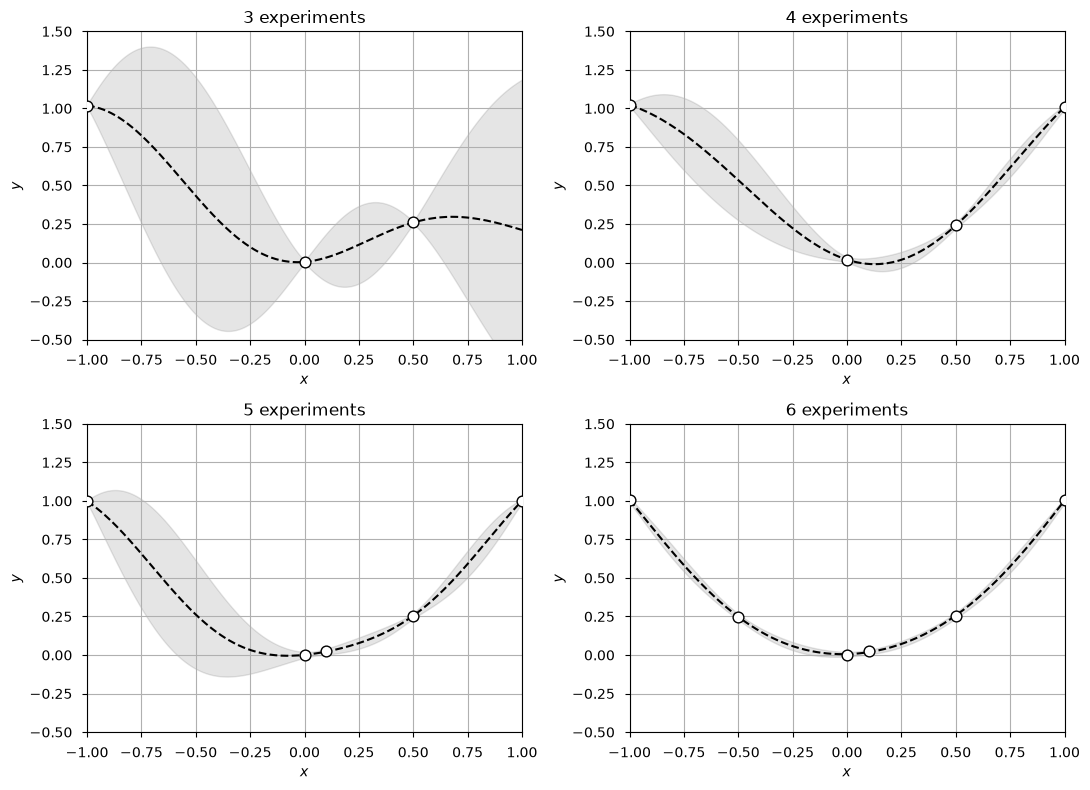

In [2]:
fig, axs = plt.subplots(2, 2, figsize=(11, 8))
for ax, design in zip(axs.ravel(), designs):
    x_omega = np.array(design).reshape(-1, 1)
    y_omega = x_omega.ravel()**2 + 0.01 * np.random.randn(len(design))
    kernel = ConstantKernel(1.0, (1e-4, 1e1)) * RBF(1, (1e-4, 1e1))
    gp = GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10, alpha=0.01**2, random_state=0)
    gp.fit(x_omega, y_omega)
    m_x, sigma_x = gp.predict(x, return_std=True)
    ax.fill_between(x.ravel(), m_x - 1.96*sigma_x, m_x + 1.96*sigma_x, color='k', alpha=0.1)
    ax.plot(x, m_x, '--k', linewidth=1.5)
    ax.scatter(x_omega, y_omega, edgecolor='black', facecolor='white', s=60, zorder=3)
    ax.set_title(f'{len(design)} experiments')
    ax.set_xlim(-1, 1); ax.set_ylim(-0.5, 1.5)
    ax.tick_params(pad=7)
    ax.set_xlabel('$x$'); ax.set_ylabel('$y$')
    ax.grid(True)
plt.tight_layout()
plt.show()

**The math, from scratch.** For the last design (6 experiments), compute $m(x)=\mathbf{k}(x)^T\mathbf{C}^{-1}\mathbf{y}$ and $\sigma^2(x)=k(x,x)-\mathbf{k}(x)^T\mathbf{C}^{-1}\mathbf{k}(x)$ with linear algebra. The next experiment goes where $\sigma(x)$ is largest.

In [3]:
c, ell = gp.kernel_.k1.constant_value, gp.kernel_.k2.length_scale
def k(a, b):
    return c * np.exp(-(a - b.T)**2 / (2 * ell**2))      # columns a, b -> matrix

C = k(x_omega, x_omega) + 0.01**2 * np.eye(len(x_omega))
kx = k(x, x_omega)                                       # one row k(x)^T per point
m_scratch = kx @ np.linalg.solve(C, y_omega)
v = c - np.sum(kx * np.linalg.solve(C, kx.T).T, axis=1)
s_scratch = np.sqrt(np.maximum(v, 0))
print(f"largest difference from scikit-learn: mean {np.abs(m_scratch - m_x).max():.1e}, SD {np.abs(s_scratch - sigma_x).max():.1e}")
print(f"next experiment (largest uncertainty): x = {x[np.argmax(sigma_x), 0]:.2f}")

largest difference from scikit-learn: mean 3.5e-14, SD 4.2e-14
next experiment (largest uncertainty): x = -0.79


**Note:** As in the book, the GP recommends experiments that reduce prediction uncertainty, balancing exploration and exploitation.